## Business Objective

The goal is not only to predict default, but to support credit risk decision-making.

In practice, the bank must decide:
- Which customers to flag for review?
- How many false positives are acceptable?
- What recall level is required for regulatory or risk appetite reasons?

Model performance must therefore be evaluated beyond ROC-AUC, focusing on:
- Precision
- Recall
- Threshold selection
- Portfolio impact


In [1]:
from pathlib import Path
import os
import sys

#check project root
current_path = Path.cwd()

if current_path.name == "notebooks":
    PROJECT_ROOT = current_path.parent
elif current_path.name == "mortgage-default-prediction":
    PROJECT_ROOT = current_path
else:
    PROJECT_ROOT = current_path

os.chdir(PROJECT_ROOT)
sys.path.append(str(PROJECT_ROOT))

print("Working directory:", Path.cwd())

Working directory: /path/to/mortgage-default-prediction


In [2]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    confusion_matrix
)
import seaborn as sns


In [3]:
df = pd.read_csv("data/processed/df_model_v1.csv")

target_col = "target"

categorical_cols = ["age_group", "cust_segment"]
numeric_cols = [
    "num_products",
    "n_days_sum",
    "neg_days_sum",
    "bal_mean_mean",
    "bal_std_mean",
    "bal_min_mean",
    "bal_max_mean",
    "neg_ratio_mean",
]

X = df[categorical_cols + numeric_cols]
y = df[target_col]


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y,
)


In [5]:
best_rf = joblib.load("model/random_forest_model.pkl")
model_metadata = joblib.load("model/model_metadata.pkl")
print(model_metadata)



{'model_name': 'RandomForest', 'test_auc': 0.834275, 'features': ['age_group', 'cust_segment', 'num_products', 'n_days_sum', 'neg_days_sum', 'bal_mean_mean', 'bal_std_mean', 'bal_min_mean', 'bal_max_mean', 'neg_ratio_mean']}


In [6]:
y_proba = best_rf.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, y_proba)
print(f"Test ROC-AUC: {auc:.4f}")


Test ROC-AUC: 0.8343


### Build a threshold performance table

In [7]:
thresholds = np.arange(0.1, 0.91, 0.1)
results = []

for t in thresholds:
    y_pred = (y_proba >= t).astype(int)

    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        "threshold": round(float(t), 2),
        "precision": round(float(precision), 3),
        "recall": round(float(recall), 3),
        "f1": round(float(f1), 3),
        "flagged_rate": round(float(y_pred.mean()), 3),
    })

threshold_df = pd.DataFrame(results)
display(threshold_df)


,threshold,precision,recall,f1,flagged_rate
0,0.1,0.372,0.880,0.523,0.473
1,0.2,0.468,0.783,0.586,0.335
2,0.3,0.509,0.657,0.574,0.258
3,0.4,0.558,0.563,0.561,0.202
4,0.5,0.594,0.430,0.499,0.145
5,0.6,0.673,0.247,0.361,0.073
6,0.7,0.824,0.093,0.168,0.023
7,0.8,0.833,0.017,0.033,0.004
8,0.9,0.000,0.000,0.000,0.000


### Threshold analysis conclusion

The threshold analysis shows a clear trade-off between recall (capturing defaulters) and precision (avoiding false positives).

At low thresholds (0.1–0.2), recall is very high but nearly half of customers are flagged, which may be operationally costly.

Around threshold 0.4, precision and recall are balanced (~0.55–0.58) and the flagged rate (~21%) is close to the portfolio default rate (20%), making this a reasonable business operating point.

Higher thresholds (≥0.5) increase precision but substantially reduce recall, resulting in a more conservative strategy that misses many defaulters.

### Confusion Matrix at Threshold = 0.4

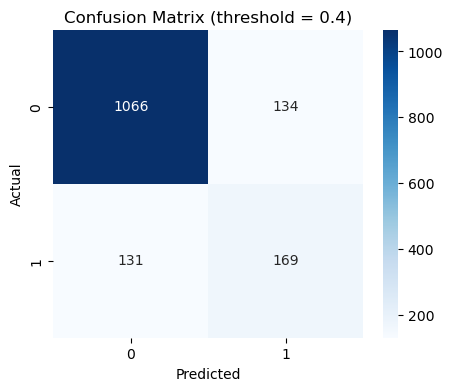

In [8]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

chosen_threshold = 0.4
y_pred = (y_proba >= chosen_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix (threshold = {chosen_threshold})")
plt.show()


### Interpretation (Threshold = 0.4)

At a decision threshold of 0.4:

- 173 out of 300 defaulters are correctly identified (Recall ≈ 58%).
- 141 non-defaulters are incorrectly flagged (False Positives).
- Approximately 21% of customers are flagged overall.

This threshold provides a balanced trade-off between risk detection and operational cost.
Lower thresholds would increase recall but also raise false positives,
while higher thresholds would reduce intervention volume but miss more risky customers.


### Simple Cost Simulation

In [9]:
cost_fn = 10000   # cost of false negative
cost_fp = 500     # cost of false positive

cost_results = []

for t in thresholds:
    y_pred = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    
    total_cost = fn * cost_fn + fp * cost_fp
    
    cost_results.append({
        "threshold": t,
        "total_cost": total_cost
    })

pd.DataFrame(cost_results)


,threshold,total_cost
0,0.1,582500
1,0.2,783500
2,0.3,1125000
3,0.4,1377000
4,0.5,1754000
5,0.6,2278000
6,0.7,2723000
7,0.8,2950500
8,0.9,3000000


### Cost-based Threshold Selection

Under the assumed cost structure:
- False Negative (missed default): €10,000
- False Positive (incorrectly flagged customer): €500

The economically optimal threshold is 0.1, minimizing total expected loss.

This highlights that threshold selection should be guided by business loss asymmetry rather than generic metrics such as F1-score.

If missing a defaulter is substantially more expensive than reviewing a good customer, a lower threshold is economically justified.


### Data Quality Considerations

Although the datasets are anonymized and simplified, exploratory analysis revealed some typical real-world imperfections:
* Missing values in certain balance-related fields
* Aggregation assumptions when combining product-level data to customer-level features
* Class imbalance (20% default rate)
* Potential temporal simplifications (no time dynamics in modeling)

These limitations reflect real banking data challenges and should be considered when interpreting model performance and business impact.

Future improvements could include:

* Temporal modeling of balance trajectories
* Additional behavioral signals=
* More robust validation using time-based splits